Anas Alhamzi - 2240003869

In [ ]:
!pip install opencv-python

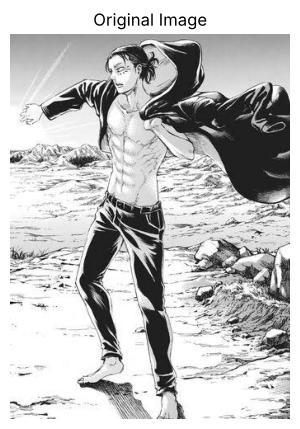

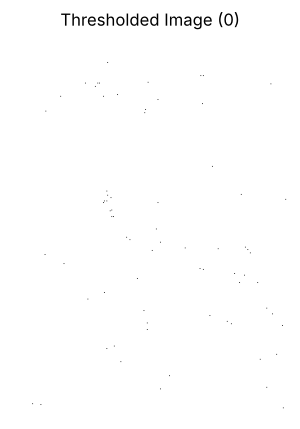

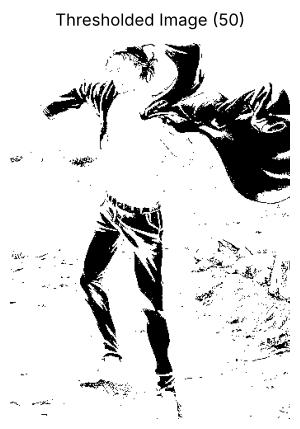

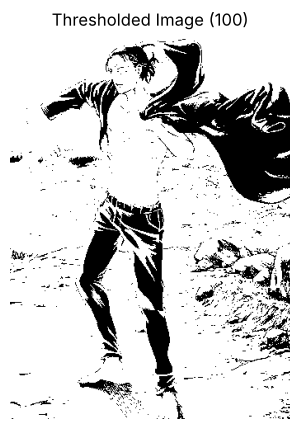

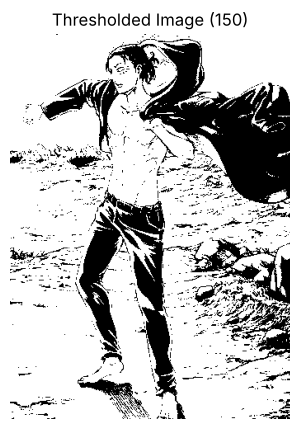

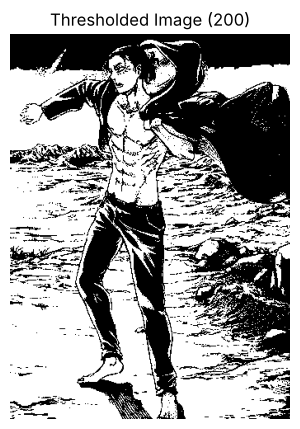

In [1]:
import cv2
import matplotlib.pyplot as plt

image_path = 'input.png'

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"Could not load image at '{image_path}'. Put input.png next to this notebook.")


plt.figure(figsize=(5, 5))
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

threshold_values = [0, 50, 100, 150, 200]

for threshold_value in threshold_values:
    ret, thresh = cv2.threshold(img, threshold_value, 255, cv2.THRESH_BINARY)
        
    plt.figure(figsize=(5, 5))
    plt.imshow(thresh, cmap='gray')
    plt.title(f'Thresholded Image ({threshold_value})')
    plt.axis('off')
    plt.show()

In [ ]:
!pip install scikit-image

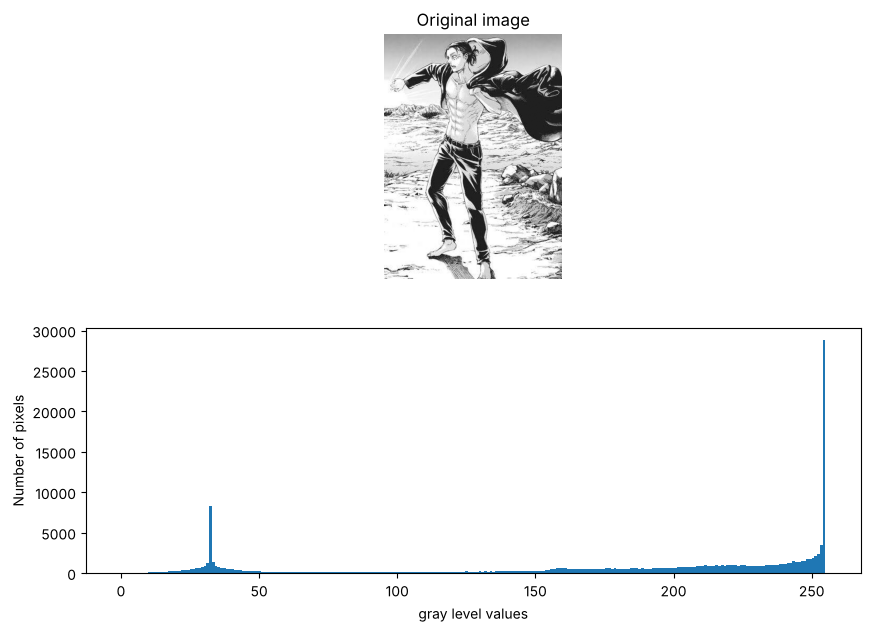

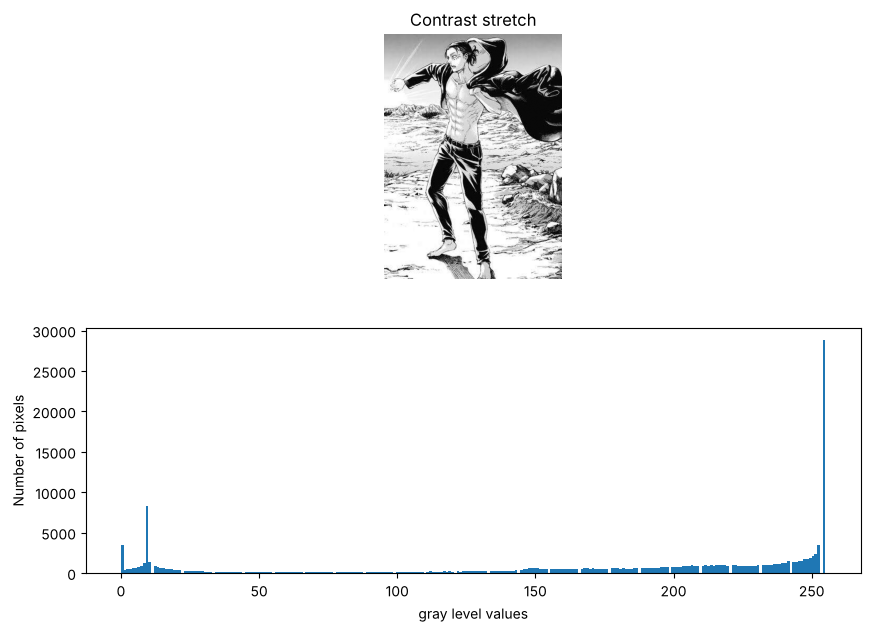

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from skimage import data, exposure

img = cv2.imread('input.png', cv2.IMREAD_GRAYSCALE)

p2, p98 = np.percentile(img, (2, 98))
img_rescale = exposure.rescale_intensity(img, in_range=(p2, p98))

fig = plt.figure(figsize=(10, 7))
fig.add_subplot(2, 1, 1)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.title('Original image')

fig.add_subplot(2, 1, 2)
plt.hist(img.flat, bins=256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()

fig = plt.figure(figsize=(10, 7))
fig.add_subplot(2, 1, 1)
plt.imshow(img_rescale, cmap='gray')
plt.axis('off')
plt.title('Contrast stretch')

fig.add_subplot(2, 1, 2)
plt.hist(img_rescale.flat, bins=256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()

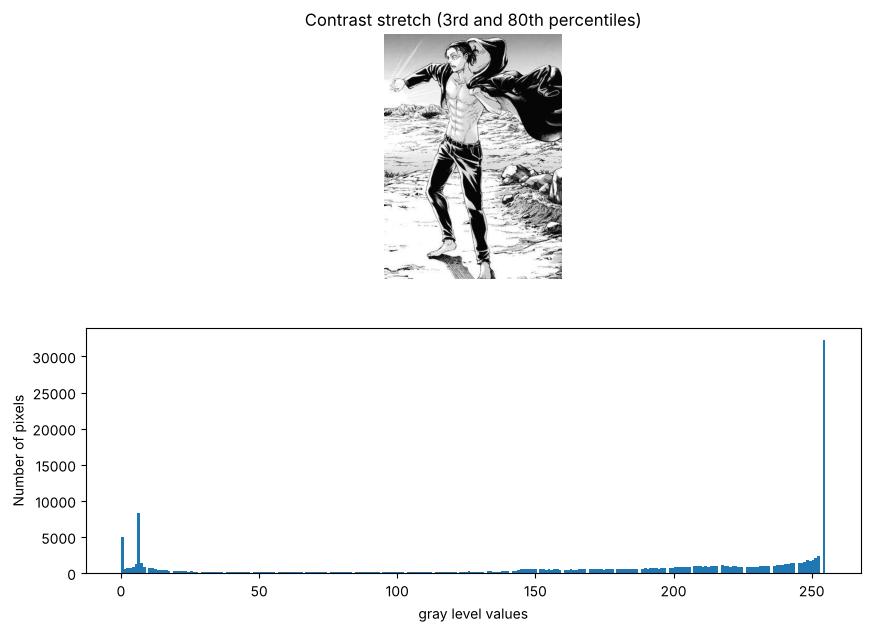

In [3]:
p3, p80 = np.percentile(img, (3, 80))
img_rescale_custom = exposure.rescale_intensity(img, in_range=(p3, p80))

fig = plt.figure(figsize=(10, 7))
fig.add_subplot(2, 1, 1)
plt.imshow(img_rescale_custom, cmap='gray')
plt.axis('off')
plt.title('Contrast stretch (3rd and 80th percentiles)')

fig.add_subplot(2, 1, 2)
plt.hist(img_rescale_custom.flat, bins=256, range=(0, 255))
plt.xlabel('gray level values')
plt.ylabel('Number of pixels')
plt.show()

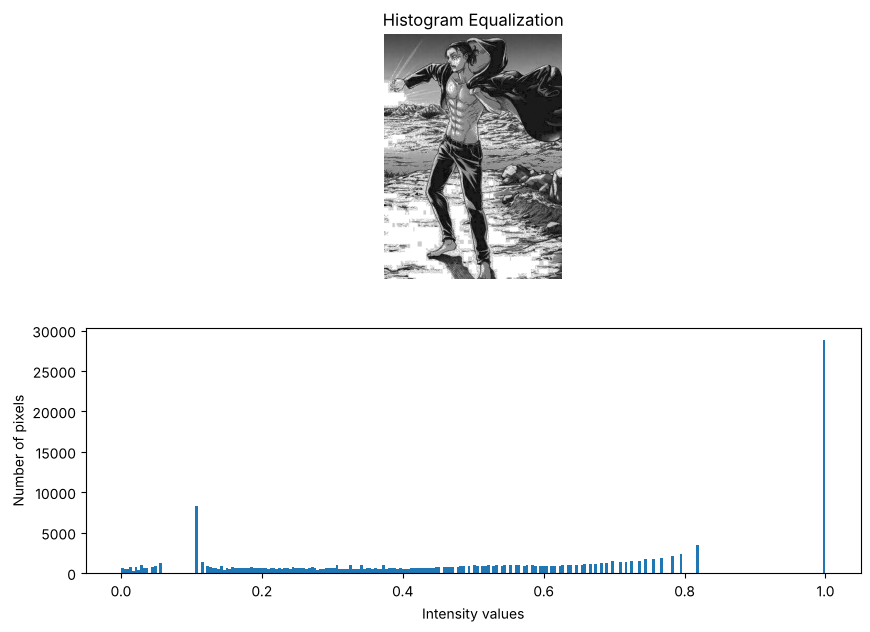

In [4]:
img_eq = exposure.equalize_hist(img)

fig = plt.figure(figsize=(10, 7))
fig.add_subplot(2, 1, 1)
plt.imshow(img_eq, cmap='gray')
plt.axis('off')
plt.title('Histogram Equalization')

fig.add_subplot(2, 1, 2)
plt.hist(img_eq.flat, bins=256, range=(0, 1))
plt.xlabel('Intensity values')
plt.ylabel('Number of pixels')
plt.show()

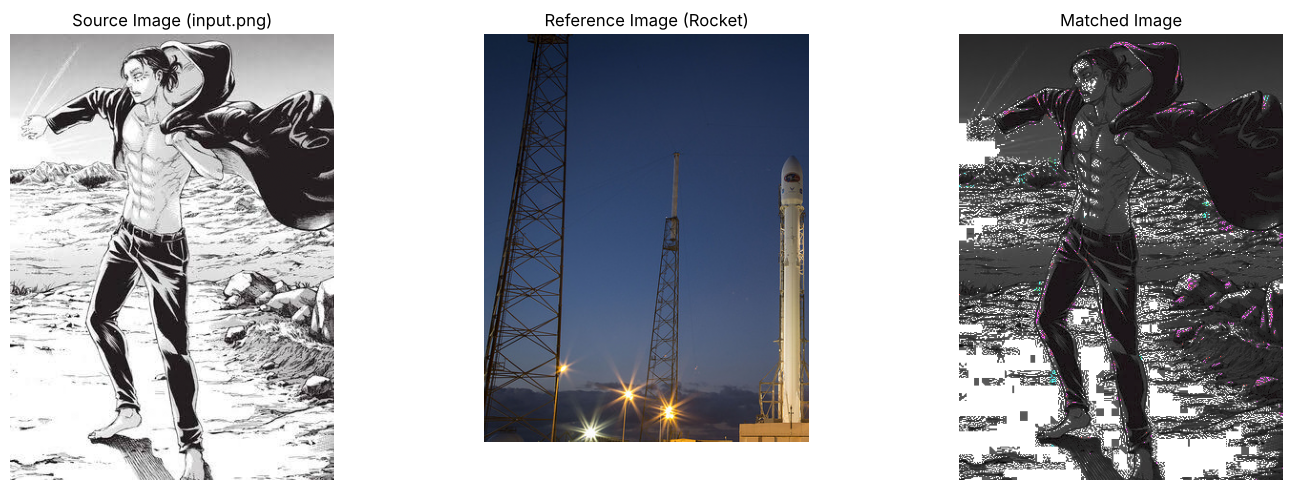

In [5]:
from skimage import img_as_float

reference = img_as_float(data.rocket())
image = img_as_float(cv2.cvtColor(cv2.imread('input.png'), cv2.COLOR_BGR2RGB))

matched = exposure.match_histograms(image, reference)

fig, (ax_source, ax_reference, ax_matched) = plt.subplots(
    1, 3, figsize=(15, 5), sharex=True, sharey=True
)

ax_source.imshow(image)
ax_source.set_title('Source Image (input.png)')
ax_source.axis('off')

ax_reference.imshow(reference)
ax_reference.set_title('Reference Image (Rocket)')
ax_reference.axis('off')

ax_matched.imshow(matched)
ax_matched.set_title('Matched Image')
ax_matched.axis('off')

plt.tight_layout()
plt.show()